<H3>PRI 2025/26: second
    project delivery</H3>

**GROUP 6**
- Catarina Gonçalves, 103989
- Isabel Costa, 106868

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import seaborn as sns
from sentence_transformers import SentenceTransformer
import nltk
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('wordnet', quiet=True)
from tqdm.auto import tqdm
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt
import json
import evaluate
from tqdm.notebook import tqdm
nltk.download('punkt_tab')
import time
from sklearn.model_selection import train_test_split
import sys
sys.path.append(os.path.abspath('../src'))
from supervised_functions import fine_tuning, fine_tuning_summaries, feature_extraction, training, summarization_supervised, supervised_evaluation
from indexing import indexing
from summarization import summarization
from evaluation_part2 import evaluation
from EDA_part2 import get_optimal_p
from unsupervised_module import sentence_clustering, summarization_clustering, keyword_extraction

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


<H2>Main facilities</H2>

Load de dataset and split it into training and testing

In [ ]:
def load_bbc_dataset(base_path):
    D = []
    categories = ['business', 'entertainment', 'politics', 'sport', 'tech']
    
    for category in categories:
        folder_path = os.path.join(base_path, category)
        if not os.path.exists(folder_path):
            continue
            
        for filename in sorted(os.listdir(folder_path)):
            if filename.endswith(".txt"):
                file_path = os.path.join(folder_path, filename)
                with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
                    text = f.read().strip()
                    if text:
                        D.append({'doc_id': f"bbc_{category}_{filename.replace('.txt', '')}",
                                  'text': text,
                                  'category': category})
    print(f"Loaded {len(D)} documents from the BBC dataset.")
    return D

D = load_bbc_dataset('../data/BBC News Summary/News Articles')
R = load_bbc_dataset('../data/BBC News Summary/Summaries')

# Split the dataset into training and testing sets (80% train, 20% test)
categories = [item['category'] for item in D]

# Guarantees that the distribution of categories is preserved in both sets
D_train, D_test, R_train, R_test = train_test_split(D, R,
                                                    test_size=0.2,       
                                                    stratify=categories, 
                                                    random_state=42)

print(f"Training set size: {len(D_train)} articles/summaries")
print(f"Testing set size: {len(D_test)} articles/summaries")

Loaded 2225 documents from the BBC dataset.
Loaded 2225 documents from the BBC dataset.
Training set size: 1780 articles/summaries
Testing set size: 445 articles/summaries


<h3>Part I: supervised IR</h3>

**II.1 Fine-tuning abstractive summarizers**

*A) Solution*

In [4]:
# T5 - lightweight summarizer
M = "t5-small" 

args = {"epochs": 5, 
        "batch_size": 4,
        "learning_rate": 5e-5,
        "save_path": "./my_best_t5_model"}

print(f"Starting fine-tuning for {M}...")
fine_tuned_model = fine_tuning(M, D_train, R_train, args)

Starting fine-tuning for t5-small...


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Map:   0%|          | 0/1780 [00:00<?, ? examples/s]

Starting fine-tuning...


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,No log,0.552171,16.180400,11.583000,14.922100,16.159700
2,1.010965,0.512056,18.998500,15.363700,17.891400,18.961800
3,0.640632,0.496315,19.652000,15.919900,18.590700,19.621500
4,0.615784,0.489195,20.079400,16.131700,19.043900,20.102700
5,0.597579,0.487960,20.093200,16.091500,19.067600,20.107600


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to ./my_best_t5_model


*B) Evaluation*

In [5]:
# BASELINE VS. FINE-TUNED COMPARISON
print("\n--- Generating Summaries on the testing set ---")
save_directory = "./my_best_t5_model"

# Generate summaries using both models
base_summaries = fine_tuning_summaries("t5-small", D_test)
finetuned_summaries = fine_tuning_summaries(save_directory, D_test)

# Match the true reference summaries to the test documents
ref_dict = {r['doc_id']: r['text'] for r in R_test}
true_references = [ref_dict[d['doc_id']] for d in D_test]

# Compute the ROUGE scores
rouge_metric = evaluate.load("rouge")

base_results = rouge_metric.compute(predictions=base_summaries, references=true_references, use_stemmer=True)
finetuned_results = rouge_metric.compute(predictions=finetuned_summaries, references=true_references, use_stemmer=True)

# Print results
print("\n=== FINAL ROUGE COMPARISON ON TEST SET ===")
print(f"{'Metric':<10} | {'Base t5-small':<15} | {'Fine-Tuned t5-small':<20}")
print("-" * 50)
print(f"{'ROUGE-1':<10} | {base_results['rouge1']*100:.2f}%{'':<9} | {finetuned_results['rouge1']*100:.2f}%")
print(f"{'ROUGE-2':<10} | {base_results['rouge2']*100:.2f}%{'':<9} | {finetuned_results['rouge2']*100:.2f}%")
print(f"{'ROUGE-L':<10} | {base_results['rougeL']*100:.2f}%{'':<9} | {finetuned_results['rougeL']*100:.2f}%")


--- Generating Summaries on the testing set ---


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Generating with t5-small:   0%|          | 0/445 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Generating with ./my_best_t5_model:   0%|          | 0/445 [00:00<?, ?it/s]

Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both


=== FINAL ROUGE COMPARISON ON TEST SET ===
Metric     | Base t5-small   | Fine-Tuned t5-small 
--------------------------------------------------
ROUGE-1    | 32.05%          | 51.97%
ROUGE-2    | 21.10%          | 39.04%
ROUGE-L    | 23.39%          | 38.57%


**II.2 Classification-based summarizers**

*A) Feature extraction*

In [6]:
# Creating Index (from delivery 1)
args_doc = {'level': 'sentence', 'encoder_models': ['BAAI/bge-small-en-v1.5']}

print("Initializing hybrid indexing process (Lexical TF-IDF + Semantic LLM)...")

I, time_taken, memory_size_mb = indexing(D_train, args_doc)

print("-" * 50)
print("INDEXING COMPLETE")
print("-" * 50)

# Feature Extraction (sentence length, relative position, TF-IDF and BERT)
encoder = SentenceTransformer('BAAI/bge-small-en-v1.5')
args = {'encoder': encoder}

X_train = []
sentence_texts = []

# Loop on the whole training dataset
doc_lookup = {str(doc['doc_id']): doc['text'] for doc in D_train}
X_train = []

for k in tqdm(range(len(I['texts']))):
    s = I['texts'][k]
    sent_id = I['ids'][k]
    
    doc_id = sent_id.split('_sent_')[0] 
    d = doc_lookup[doc_id]
    features = feature_extraction(s, d, I, args)
    
    # Save the results
    X_train.append(features)
    sentence_texts.append(s)

X_train = np.array(X_train)

print(f"Extraction complete! Feature Matrix Shape: {X_train.shape}")

Initializing hybrid indexing process (Lexical TF-IDF + Semantic LLM)...
Building Lexical Index (TF-IDF) for 32782 items...
Building Semantic Index using LLM: BAAI/bge-small-en-v1.5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1025 [00:00<?, ?it/s]

Indexing Complete! Level: sentence | Time: 208.44s | Size: 48.02 MB
--------------------------------------------------
INDEXING COMPLETE
--------------------------------------------------


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/32782 [00:00<?, ?it/s]

Extraction complete! Feature Matrix Shape: (32782, 4)


*B) Classification*

In [7]:
# Train the Random Forest Model
print("--- Training Random Forest ---")
args_rf = {'I': I, 'X_train': X_train, 
           'classifier': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)}
M_rf = training(D_train, R_train, args_rf)

# Train the Naïve Bayes Model
print("\n--- Training Naïve Bayes ---")
args_nb = {'I': I, 'X_train': X_train, 'classifier': GaussianNB()}
M_nb = training(D_train, R_train, args_nb)

--- Training Random Forest ---
Using pre-computed X_train to save time...
Labeling complete. Found 3673 summary sentences out of 32782 total.
Fitting the classification model ...
Model training complete!

--- Training Naïve Bayes ---
Using pre-computed X_train to save time...
Labeling complete. Found 3673 summary sentences out of 32782 total.
Fitting the classification model ...
Model training complete!


*C) Ranking extension*

In [8]:
# Define specific 'p' (sentence) limits for each category 
p_limits = {'business': 4, 
            'entertainment': 4, 
            'politics': 6, 
            'sport': 4, 
            'tech': 6}

encoder = SentenceTransformer('BAAI/bge-small-en-v1.5')
args = {'I': I, 'encoder': encoder}

generated_summaries_rf = []
generated_summaries_nb = []

print(f"Generating summaries for {len(D_test)} documents...")

for doc in tqdm(D_test, desc="Processing Test Set"):
    d = doc['text']
    category = doc['category']
    doc_id = doc['doc_id']
    
    # Get the specific 'p' for this document's category
    p = p_limits.get(category, 5) 

    # Summarization for Random Forest and Naïve Bayes
    summary_text_rf = summarization_supervised(d, M_rf, p, None, args)
    summary_text_nb = summarization_supervised(d, M_nb, p, None, args) 
    
    # Save the result
    generated_summaries_rf.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_rf})
    generated_summaries_nb.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_nb})

# Displaying one example summary from each model and the ground-truth for comparison
idx = 0
print(f"Document ID: {generated_summaries_rf[idx]['doc_id']}")

print("\n Random Forest summary:")
print(generated_summaries_rf[idx]['summary'])

print("\n Naïve Bayes summary:")
print(generated_summaries_nb[idx]['summary'])

print("\n Ground-Truth summary:")
print(R_test[idx]['text'])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Generating summaries for 445 documents...


Processing Test Set:   0%|          | 0/445 [00:00<?, ?it/s]

Document ID: bbc_business_264

 Random Forest summary:
Deutsche Boerse previously offered £1.3bn, which was rejected by the LSE, while Euronext is rumoured to have facilities in place to fund a £1.4bn cash bid. But a deal with either bidder would create the biggest stock market operator in Europe and the second biggest in the world after the New York Stock Exchange. Meanwhile, LSE shareholders fear that Deutsche Boerse's control over its Clearstream unit - the clearing house that processes securities transactions - would create a monopoly situation. Commentators believe Deutsche Boerse, which has now formally asked German authorities to approve its plan to buy the LSE, may offer to sell Clearstream to gain shareholder approval.

 Naïve Bayes summary:
French suitor holds LSE meeting

European stock market Euronext has met with the London Stock Exchange (LSE) amid speculation that it may be ready to launch a cash bid. But a deal with either bidder would create the biggest stock market op

*D) Evaluation*

In [9]:
# SUPERVISED EVALUATION - Project II
args={'I': I, 'encoder': encoder}

# Random Forest and  Naïve Bayes supervised evaluation scores
rf_supervised_scores = supervised_evaluation(D_test, R_test, M_rf, args)
nb_supervised_scores = supervised_evaluation(D_test, R_test, M_nb, args)
print("\n" + "="*40)
print("SUPERVISED EVALUATION RESULTS")
print("="*40)

print("Random Forest:")
print(f" Precision: {rf_supervised_scores['precision']:.4f}")
print(f" Recall:    {rf_supervised_scores['recall']:.4f}")
print(f" F1-Score:  {rf_supervised_scores['f1_score']:.4f}")
print(f" AUC:       {rf_supervised_scores['auc']:.4f}")

print("\nNaïve Bayes:")
print(f" Precision: {nb_supervised_scores['precision']:.4f}")
print(f" Recall:    {nb_supervised_scores['recall']:.4f}")
print(f" F1-Score:  {nb_supervised_scores['f1_score']:.4f}")
print(f" AUC:       {nb_supervised_scores['auc']:.4f}")
print("="*40)

# EVALUATION - Project I
# Format lists into dictionaries
S_set_rf = {doc['doc_id']: doc['summary'] for doc in generated_summaries_rf}
S_set_nb = {doc['doc_id']: doc['summary'] for doc in generated_summaries_nb}
R_set_truth = {doc['doc_id']: doc['text'] for doc in R_test} 

# Map the categories for the weighted F-beta score
doc_categories = {doc['doc_id']: doc['category'] for doc in D_test}

# Define the evaluation arguments 
args_extractive = {"eval_mode": "extractive", "doc_categories": doc_categories}

# Calculate Extractive Scores (Precision, Recall, F-beta)
print("Calculating Project I Extractive metrics...")
rf_scores_ext = evaluation(S_set_rf, R_set_truth, args_extractive)
nb_scores_ext = evaluation(S_set_nb, R_set_truth, args_extractive)

# Print the ultimate comparison table
print("\n" + "="*60)
print(f"{'FINAL EVALUATION RESULTS':^60}")
print("="*60)
print(f"{'Metric':<25} | {'Random Forest':<15} | {'Naïve Bayes':<15}")
print("-" * 60)

# Merge the macro dictionaries so we can print them all at once
rf_all_macros = rf_scores_ext.get('macro_averages', {})
nb_all_macros = nb_scores_ext.get('macro_averages', {})

# Print everything
for metric_name in rf_all_macros.keys():
    rf_val = rf_all_macros.get(metric_name, 0)
    nb_val = nb_all_macros.get(metric_name, 0)
    
    print(f"{metric_name:<25} | {rf_val:<15.4f} | {nb_val:<15.4f}")

print("="*60)

Extracting features and ground-truth labels for evaluation...

--- Prediction Results ---
Total sentences tested: 8638
Sentences actually in ground truth (y_true = 1): 955
Sentences model PREDICTED as summary (y_pred = 1): 421.0
----------------------------

[[7498  185]
 [ 719  236]]
Extracting features and ground-truth labels for evaluation...

--- Prediction Results ---
Total sentences tested: 8638
Sentences actually in ground truth (y_true = 1): 955
Sentences model PREDICTED as summary (y_pred = 1): 971.0
----------------------------

[[7097  586]
 [ 570  385]]

SUPERVISED EVALUATION RESULTS
Random Forest:
 Precision: 0.5606
 Recall:    0.2471
 F1-Score:  0.3430
 AUC:       0.8251

Naïve Bayes:
 Precision: 0.3965
 Recall:    0.4031
 F1-Score:  0.3998
 AUC:       0.8188
Calculating Project I Extractive metrics...

                  FINAL EVALUATION RESULTS                  
Metric                    | Random Forest   | Naïve Bayes    
------------------------------------------------

<h3>Part II: unsupervised IR</h3>

*A) Clustering*

In [10]:
test_encoder = SentenceTransformer("all-MiniLM-L6-v2") 

all_clustering_results = []

print(f"Starting dynamic, category-aware clustering for all {len(D)} documents...")

for i, doc in enumerate(D):
    
    # Set up the arguments
    cluster_args = {"encoder": test_encoder }

    # Run the function 
    C = sentence_clustering(doc, args=cluster_args)
    all_clustering_results.append(C)

    # Only print the full detailed output for the first 2 documents
    if i < 2:
        category = doc.get('category', 'unknown').upper()
        print(f"Testing on Document {i+1}: {doc.get('doc_id', 'Unknown')} (Category: {category})")
        print("--- Clustering Output ---")

        print(f"[ Dynamically Found Clusters ] -> {C.get('num_clusters_found', 'N/A')}")

        sil_score = C.get('silhouette_score')
        score_str = f"{sil_score:.4f}" if sil_score is not None else "N/A"
        print(f"[ Best Silhouette Score ] -> {score_str}")

        print(f"[ Raw Cluster Assignments ] -> {C['clusters']}")
        
        print(f"\n[ Embeddings Extracted ] -> Matrix Shape: {C['embeddings'].shape}")
                
        for cluster_id, sentence_indices in C["clusters"].items():
            print(f"\n[ Cluster {cluster_id} ] - Contains {len(sentence_indices)} sentences:")
            
            for idx in sentence_indices:
                print(f"  -> Sentence {idx}: {C['sentences'][idx]}")
                
        print("\n" + "="*50 + "\n")


print(f"\nFinished clustering all {len(D)} documents successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Starting dynamic, category-aware clustering for all 2225 documents...
Testing on Document 1: bbc_business_001 (Category: BUSINESS)
--- Clustering Output ---
[ Dynamically Found Clusters ] -> 4
[ Best Silhouette Score ] -> 0.2156
[ Raw Cluster Assignments ] -> {0: [0, 2, 6, 9, 10, 11, 12, 14], 1: [1, 3, 4, 5, 7, 8, 15, 18, 19], 2: [13], 3: [16, 17]}

[ Embeddings Extracted ] -> Matrix Shape: (20, 384)

[ Cluster 0 ] - Contains 8 sentences:
  -> Sentence 0: Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.
  -> Sentence 2: TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn.
  -> Sentence 6: It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters.
  -> Sentence 9: TimeWarner also has to restate 2000 and 2003 results following a probe by the US Securities Exchange Commission (SEC), which is close to conc

*B) Summarization*

In [11]:
# Create a list to store all the final summaries
all_summaries = []

print(f"Starting summarization for all {len(D)} documents...")

for i, (doc, C) in enumerate(zip(D, all_clustering_results)):
    
    # 1. Run the summarization_clustering function
    summary = summarization_clustering(doc, C)
    
    # 2. Store the summary in our list
    all_summaries.append(summary)
    
    # 3. Only print the output for the first 2 documents
    if i < 2:
        print(f"Document {i+1}: {doc['doc_id']}")
        
        print("\n[ Original text ]")
        print(doc['text'] + "\n")        
        print("[ Extractive Summary ]")
        print(summary)
        print("\n" + "="*50 + "\n")

print(f"\nFinished summarizing all {len(D)} documents successfully!")

Starting summarization for all 2225 documents...
Document 1: bbc_business_001

[ Original text ]
Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers

*C) Keyword extraction*

In [12]:
# Create a list to store all the extracted keywords for the entire dataset
all_extracted_keywords = []

keyword_args = {"encoder": test_encoder }

print(f"Starting dynamic, clustered keyword extraction for all {len(D)} documents...")

# Loop through every document in your dataset
for i, doc in enumerate(D):
    
    top_keywords = keyword_extraction(doc, args=keyword_args)
    
    all_extracted_keywords.append(top_keywords)
    
    # Only print the full output for the first 2 documents
    if i < 2:
        print(f"Document {i+1}: {doc.get('doc_id', 'Unknown ID')} | Category: {doc.get('category', 'unknown').upper()}")
        
        print("\n[ Original full text ]")
        print(doc.get('text', '') + "\n")
        
        print(f"[ Dynamically Extracted {len(top_keywords)} Keywords ]")
        for rank, word in enumerate(top_keywords, 1):
            print(f"{rank}. {word}")
            
        print("\n" + "="*70 + "\n")

print(f"\nFinished extracting diverse keywords for all {len(D)} documents successfully!")

Starting dynamic, clustered keyword extraction for all 2225 documents...
Document 1: bbc_business_001 | Category: BUSINESS

[ Original full text ]
Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet adve

*D) Evaluation*

In [13]:
# Create dictionaries to hold the generated summaries (S_set),  reference summaries (R_set), and document categories
S_set = {}
R_set = {}
doc_categories = {}
time_clustering = 0.0
time_clu_indiv = {} 

# Convert your 'R' list into a lookup dictionary using doc_id
R_lookup = {item['doc_id']: item['text'] for item in R}

# Define the args for your summarizer so it has the mathematical encoder
summarizer_args = {"encoder": test_encoder}

print(f"Starting summarization and evaluation prep for all {len(D)} documents...\n")

first_two_docs = [] 

# Loop through every document in your dataset D
for i, doc in enumerate(D):
    doc_id = doc.get('doc_id')
    category = doc.get('category', 'unknown')
    
    # Grab the corresponding reference summary from our lookup dictionary
    reference_text = R_lookup.get(doc_id, "")
    
    start_t = time.time() 
    
    # --- SUMMARIZATION PIPELINE ---
    # Step A: Cluster the sentences
    C_solution = sentence_clustering(doc, args=summarizer_args)
    
    # Step B: Extract the prototype sentences to form the summary
    generated_summary = summarization_clustering(doc, C_solution, args=summarizer_args) 
    
    doc_time = time.time() - start_t 
    time_clustering += doc_time      
    time_clu_indiv[doc_id] = doc_time     
     
    if isinstance(generated_summary, list):
        generated_summary = " ".join(generated_summary)
        
    
    S_set[doc_id] = generated_summary
    R_set[doc_id] = reference_text
    doc_categories[doc_id] = category
    
    # Only print the full text output for the first 2 documents
    if i < 2:
        first_two_docs.append(doc_id) # Save the ID for later!
        print(f"Document {i+1}: {doc_id} | Category: {category.upper()}")
        print(f"Execution Time: {doc_time:.4f} seconds") 
        print("-" * 50)
        print("[ Ground Truth Summary (R_text) ]")
        print(reference_text + "\n") # Full text printed
        print("[ Generated Summary (S_text) ]")
        print(generated_summary + "\n") # Full text printed
        print("=" * 70 + "\n")

print("Finished generating summaries! Now running the Evaluation Engine...\n")
print(f"Clustering Generation Complete! Total Time: {time_clustering:.2f} seconds\n")

# Set up the arguments for the evaluation function
eval_args = {"eval_mode": "extractive", "doc_categories": doc_categories}
    
final_results = evaluation(S_set, R_set, eval_args)

# Print the individual scores for the first 2 documents
print("Individual scores for the first two documents")
print("=" * 50)
doc_scores = final_results.get("document_scores", {})
for doc_id in first_two_docs:
    print(f"Metrics for {doc_id}:")
    metrics = doc_scores.get(doc_id, {})
    for metric, score in metrics.items():
        print(f"  - {metric:<15}: {score:.4f}")
    print("-" * 50)

# Print the final dataset-wide scores
print("\n Final Macro Averages (entire dataset) ")
print("=" * 50)
macro_scores = final_results.get("macro_averages", {})

if macro_scores:
    for metric, score in macro_scores.items():
        print(f"{metric:<25}: {score:.4f}")
else:
    print("No metrics returned. Check if ground truth summaries were missing!")
print("=" * 50)

Starting summarization and evaluation prep for all 2225 documents...

Document 1: bbc_business_001 | Category: BUSINESS
Execution Time: 0.0165 seconds
--------------------------------------------------
[ Ground Truth Summary (R_text) ]
TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn.For the full-year, TimeWarner posted a profit of $3.36bn, up 27% from its 2003 performance, while revenues grew 6.4% to $42.09bn.Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues.Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.For 2005, TimeWarner is projecting operating earnings growth of around 5%, and also expects higher revenue and wider profit margins.It lost 464,000 subscribers in the fourth quarter profit

<H2>Questions</H2>

**Part I: supervised IR**

**(1)** According to ROUGE, how the fine-tuning setup (e.g. number of epochs) impacts performance?


Starting fine-tuning for t5-small with LR = 1e-05...


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Map:   0%|          | 0/1780 [00:00<?, ? examples/s]

Starting fine-tuning...


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,No log,0.780564,13.142700,8.464600,11.591300,13.156700
2,1.778764,0.645909,9.965700,7.089600,9.061800,9.977900
3,0.912996,0.614822,9.870300,6.739200,8.953800,9.813100
4,0.855408,0.602658,12.163600,8.256000,10.924100,12.172800
5,0.826675,0.598152,12.188600,8.255400,10.944500,12.217700


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (27 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to ./t5_model_lr_5e-05


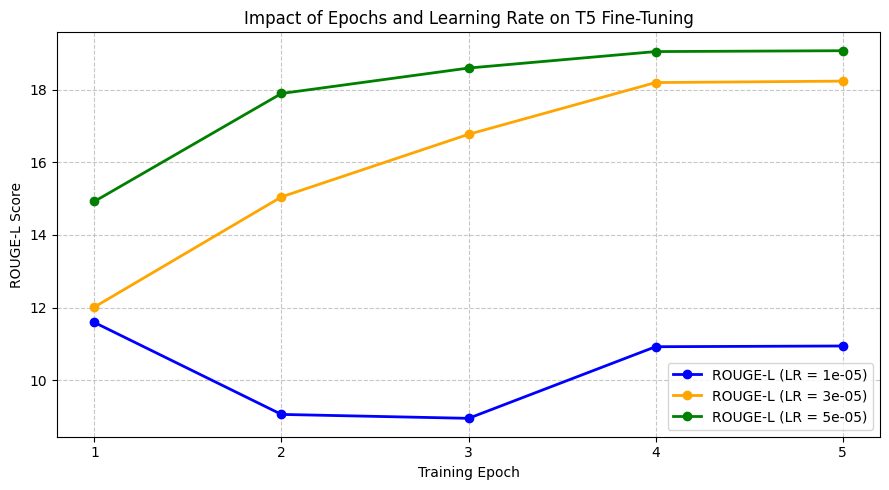

In [14]:
# PLOT ROUGE SCORE PER EPOCH FOR DIFFERENT LEARNING RATES
learning_rates = [1e-5, 3e-5, 5e-5]
epochs_to_test = 5
M = "t5-small" 

for lr in learning_rates:
    # Create a unique folder for each model with different learning rates
    save_directory = f"./t5_model_lr_{lr}"
    
    args = {"epochs": epochs_to_test, 
            "batch_size": 4,
            "learning_rate": lr,
            "save_path": save_directory}
    
    print(f"\n{'='*50}")
    print(f"Starting fine-tuning for {M} with LR = {lr}...")
    print(f"{'='*50}")
    
    fine_tuning(M, D_train, R_train, args)

# !! LMM-aided code block
plt.figure(figsize=(9, 5))
colors = ['blue', 'orange', 'green']

for i, lr in enumerate(learning_rates):
    history_path = f"./t5_model_lr_{lr}/training_history.json"
    
    if os.path.exists(history_path):
        with open(history_path, "r") as f:
            history = json.load(f)

        epochs, rougeL = [], []
        for log in history:
            if 'eval_rougeL' in log:
                epochs.append(log['epoch'])
                rougeL.append(log['eval_rougeL'])

        # Plot the line for this specific learning rate
        plt.plot(epochs, rougeL, marker='o', color=colors[i], linewidth=2, label=f'ROUGE-L (LR = {lr})')
    else:
        print(f"Warning: Could not find {history_path}.")

plt.title("Impact of Epochs and Learning Rate on T5 Fine-Tuning")
plt.xlabel("Training Epoch")
plt.ylabel("ROUGE-L Score")
plt.xticks(range(1, epochs_to_test + 1)) 
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**(2)** How classification-based summarization affects performance?

In [15]:
# Compare the results between Random forest, Naïve Bayes (already computed) and  BM25 and MiniLM

# Creating index for all the documents 
args_doc = {'level': 'sentence', 
                 'encoder_models': ['BAAI/bge-small-en-v1.5', 'sentence-transformers/all-MiniLM-L6-v2']}
I_full, time_taken, memory_size_mb = indexing(D, args_doc)

# Define arguments for BM25 and MiniLM (Project I Unsupervised Models)
args_bm25 = {'summary_mode': 'extractive', 'model_family': 'lexical'}
args_minilm = {'summary_mode': 'extractive', 'model_family': 'semantic', 'selected_encoder': 'sentence-transformers/all-MiniLM-L6-v2'}

# Lists to store ONLY the newly generated unsupervised summaries
generated_summaries_bm25 = []
generated_summaries_minilm = []

print(f"\nGenerating Project I summaries for {len(D_test)} documents...")

for doc in tqdm(D_test, desc="Processing Test Set"):
    d_text = doc['text']
    category = doc['category']
    doc_id = doc['doc_id']
    
    p = p_limits.get(category, 5) 
    doc_sentences = nltk.sent_tokenize(d_text)
    
    # BM25 Generation
    bm25_raw_output = summarization(doc, p=p, l=None, I=I_full, args=args_bm25)
    summary_text_bm25 = " ".join([doc_sentences[pos] for pos, score in bm25_raw_output])
    
    # MiniLM Generation
    minilm_raw_output = summarization(doc, p=p, l=None, I=I_full, args=args_minilm)
    summary_text_minilm = " ".join([doc_sentences[pos] for pos, score in minilm_raw_output])
    
    generated_summaries_bm25.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_bm25})
    generated_summaries_minilm.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_minilm})

# Display one example summary from each model and the ground-truth for comparison
idx = 0
print(f"\nDocument ID: {generated_summaries_rf[idx]['doc_id']}")
print("\n[Ground-Truth summary]:\n", R_test[idx]['text'])
print("\n[Random Forest summary]:\n", generated_summaries_rf[idx]['summary'])
print("\n[Naïve Bayes summary]:\n", generated_summaries_nb[idx]['summary'])
print("\n[Semantic MiniLM summary]:\n", generated_summaries_minilm[idx]['summary'])
print("\n[Lexical BM25 summary]:\n", generated_summaries_bm25[idx]['summary'])

# END-TO-END SUMMARIZATION EVALUATION
S_set_bm25 = {doc['doc_id']: doc['summary'] for doc in generated_summaries_bm25}
S_set_minilm = {doc['doc_id']: doc['summary'] for doc in generated_summaries_minilm}
R_set_truth = {doc['doc_id']: doc['text'] for doc in R_test} 

doc_categories = {doc['doc_id']: doc['category'] for doc in D_test}
args_extractive = {"eval_mode": "extractive", "doc_categories": doc_categories}

print("\nCalculating Extractive metrics for BM25 and MiniLM...")
bm25_scores_ext = evaluation(S_set_bm25, R_set_truth, args_extractive)
minilm_scores_ext = evaluation(S_set_minilm, R_set_truth, args_extractive)

# Print the comparison table
print("\n" + "="*85)
print(f"{'FINAL EVALUATION RESULTS: PROJECT I vs PROJECT II':^85}")
print("="*85)
print(f"{'Metric':<25} | {'BM25 (Proj1)':<12} | {'MiniLM (Proj1)':<14} | {'RF (Proj2)':<12} | {'NB (Proj2)':<12}")
print("-" * 85)

# Merge all macro dictionaries
rf_all = rf_scores_ext.get('macro_averages', {})
nb_all = nb_scores_ext.get('macro_averages', {})
bm25_all = bm25_scores_ext.get('macro_averages', {})
minilm_all = minilm_scores_ext.get('macro_averages', {})

# Print everything dynamically side-by-side
for metric_name in rf_all.keys():
    rf_val = rf_all.get(metric_name, 0)
    nb_val = nb_all.get(metric_name, 0)
    bm25_val = bm25_all.get(metric_name, 0)
    minilm_val = minilm_all.get(metric_name, 0)
    
    print(f"{metric_name:<25} | {bm25_val:<12.4f} | {minilm_val:<14.4f} | {rf_val:<12.4f} | {nb_val:<12.4f}")

print("="*85)

Building Lexical Index (TF-IDF) for 41420 items...
Building Semantic Index using LLM: BAAI/bge-small-en-v1.5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1295 [00:00<?, ?it/s]

Building Semantic Index using LLM: sentence-transformers/all-MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1295 [00:00<?, ?it/s]

Indexing Complete! Level: sentence | Time: 269.49s | Size: 121.35 MB

Generating Project I summaries for 445 documents...


Processing Test Set:   0%|          | 0/445 [00:00<?, ?it/s]


Document ID: bbc_business_264

[Ground-Truth summary]:
 European stock market Euronext has met with the London Stock Exchange (LSE) amid speculation that it may be ready to launch a cash bid.Euronext, so far, has given little away as to what sweeteners it will offer the LSE - Europe's biggest equity market - into a deal.Deutsche Boerse previously offered £1.3bn, which was rejected by the LSE, while Euronext is rumoured to have facilities in place to fund a £1.4bn cash bid.Euronext chief Jean-Francois Theodore held talks with LSE boss Clara Furse the day after rival Deutsche Boerse put forward its own bid case.Commentators believe Deutsche Boerse, which has now formally asked German authorities to approve its plan to buy the LSE, may offer to sell Clearstream to gain shareholder approval.There was speculation Euronext would use Friday's meeting as an opportunity to take advantage of growing disquiet over Deutsche Boerse's own plans for dominance over the London market.Meanwhile, LSE sh

**(3.1)** Which features appear to be more relevant to the target summarization task?

Feature Ranking:
1. Sentence Length (0.3149)
2. TF-IDF Score (0.3095)
3. BERT Similarity (0.2759)
4. Relative Position (0.0997)


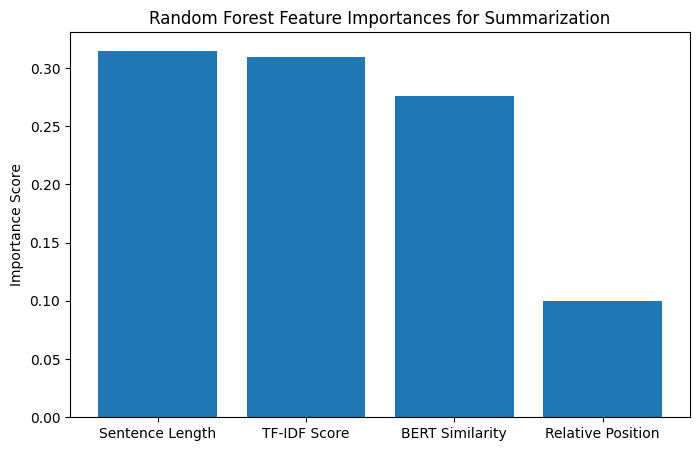

Extracting internal statistics from Naïve Bayes...

Naïve Bayes Feature Relevance (Cohen's d):
Sentence Length     : 1.1893
TF-IDF Score        : 0.9061
BERT Similarity     : 0.5949
Relative Position   : 0.0134


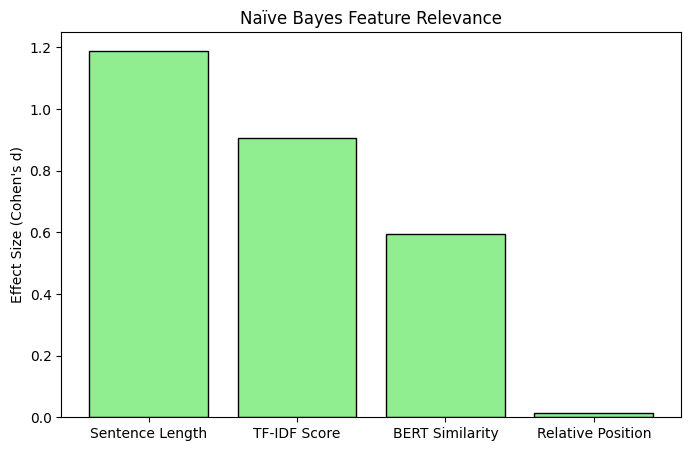

In [16]:
# Random Forest Feature Importances
feature_names = ['Sentence Length', 'Relative Position', 'TF-IDF Score', 'BERT Similarity'] 
importances = M_rf.feature_importances_

# Sort them from most important to least important
indices = np.argsort(importances)[::-1]

print("Feature Ranking:")
for f in range(len(feature_names)):
    print(f"{f+1}. {feature_names[indices[f]]} ({importances[indices[f]]:.4f})")

# Plot of Random Forest feature importances
plt.figure(figsize=(8, 5))
plt.title("Random Forest Feature Importances for Summarization")
plt.bar(range(len(feature_names)), importances[indices], align="center")
plt.xticks(range(len(feature_names)), [feature_names[i] for i in indices])
plt.ylabel("Importance Score")
plt.show()

# Naïve Bayes Feature Analysis

# !! LLM-aided code block
def nb_feature_relevance(M_nb, feature_names):
    """
    Calculates feature relevance for Gaussian Naïve Bayes using Cohen's d.
    """
    print("Extracting internal statistics from Naïve Bayes...")
    
    # Class 0 (Not Summary) and Class 1 (Summary) means
    mu_0 = M_nb.theta_[0]
    mu_1 = M_nb.theta_[1]
    
    # Class 0 and Class 1 variances
    var_0 = M_nb.var_[0]
    var_1 = M_nb.var_[1]
    
    # Calculate Cohen's d for each feature: |mu_1 - mu_0| / sqrt((var_1 + var_0) / 2)
    pooled_std = np.sqrt((var_0 + var_1) / 2.0)
    
    # Avoid division by zero just in case a feature is perfectly constant
    pooled_std[pooled_std == 0] = 1e-9 
    
    cohens_d = np.abs(mu_1 - mu_0) / pooled_std
    
    # Sort the features by their effect size
    sorted_idx = np.argsort(cohens_d)
    sorted_features = np.array(feature_names)[sorted_idx]
    sorted_scores = cohens_d[sorted_idx]
    
    # Print the ranking
    print("\nNaïve Bayes Feature Relevance (Cohen's d):")
    for feat, score in zip(reversed(sorted_features), reversed(sorted_scores)):
        print(f"{feat:<20}: {score:.4f}")
        
    # Plotting
    sorted_features_desc = sorted_features[::-1]
    sorted_scores_desc = sorted_scores[::-1]
    plt.figure(figsize=(8, 5))
    plt.title("Naïve Bayes Feature Relevance")
    plt.bar(range(len(sorted_features_desc)), sorted_scores_desc, align="center", color='lightgreen', edgecolor='black')
    plt.xticks(range(len(sorted_features_desc)), sorted_features_desc)
    plt.ylabel("Effect Size (Cohen's d)")
    plt.show()

nb_feature_relevance(M_nb, feature_names)

In [17]:
# Evaluate the impact of just using TF-IDF and BERT similarity features
args_ablation = {'I': I, 'encoder': encoder,'ablation': True }

# Train Random Forest
print("--- Training Random Forest (Ablation) ---")
args_ablation['classifier'] = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
M_rf_ablation = training(D_train, R_train, args_ablation)

# Train Naïve Bayes
print("\n--- Training Naïve Bayes (Ablation) ---")
args_ablation['classifier'] = GaussianNB()
M_nb_ablation = training(D_train, R_train, args_ablation)

p_limits = {'business': 4, 'entertainment': 4, 'politics': 6, 'sport': 4, 'tech': 6}
encoder = SentenceTransformer('BAAI/bge-small-en-v1.5')

# Generate summaries using the ablation models
generated_summaries_rf_abl = []
generated_summaries_nb_abl = []

print(f"Generating ablation summaries for {len(D_test)} documents...")

for doc in tqdm(D_test, desc="Processing Test Set"):
    d = doc['text']
    category = doc['category']
    doc_id = doc['doc_id']
    p = p_limits.get(category, 5) 

    # Pass the ablation models and the ablation args!
    summary_text_rf = summarization_supervised(d, M_rf_ablation, p, None, args_ablation)
    summary_text_nb = summarization_supervised(d, M_nb_ablation, p, None, args_ablation) 
    
    generated_summaries_rf_abl.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_rf})
    generated_summaries_nb_abl.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_nb})

# Evaluate the models
print("\n" + "="*40)
print("SUPERVISED EVALUATION RESULTS (ABLATION)")
print("="*40)

rf_supervised_scores = supervised_evaluation(D_test, R_test, M_rf_ablation, args_ablation)
nb_supervised_scores = supervised_evaluation(D_test, R_test, M_nb_ablation, args_ablation)

print("Random Forest (Ablation):")
print(f" Precision: {rf_supervised_scores['precision']:.4f} | Recall: {rf_supervised_scores['recall']:.4f} | F1: {rf_supervised_scores['f1_score']:.4f} | AUC: {rf_supervised_scores['auc']:.4f}")

print("\nNaïve Bayes (Ablation):")
print(f" Precision: {nb_supervised_scores['precision']:.4f} | Recall: {nb_supervised_scores['recall']:.4f} | F1: {nb_supervised_scores['f1_score']:.4f} | AUC: {nb_supervised_scores['auc']:.4f}")
print("="*40)

# Evaluation using Project I & II metrics
S_set_rf = {doc['doc_id']: doc['summary'] for doc in generated_summaries_rf_abl}
S_set_nb = {doc['doc_id']: doc['summary'] for doc in generated_summaries_nb_abl}
R_set_truth = {doc['doc_id']: doc['text'] for doc in R_test} 
doc_categories = {doc['doc_id']: doc['category'] for doc in D_test}

args_extractive = {"eval_mode": "extractive", "doc_categories": doc_categories}
args_abstractive = {"eval_mode": "abstractive", "eval_encoder": 'BAAI/bge-small-en-v1.5'}

rf_scores_ext = evaluation(S_set_rf, R_set_truth, args_extractive)
nb_scores_ext = evaluation(S_set_nb, R_set_truth, args_extractive)
rf_scores_abs = evaluation(S_set_rf, R_set_truth, args_abstractive)
nb_scores_abs = evaluation(S_set_nb, R_set_truth, args_abstractive)

print("\n" + "="*60)
print(f"{'FINAL ABLATION EVALUATION RESULTS':^60}")
print("="*60)
print(f"{'Metric':<25} | {'RF (Ablation)':<15} | {'NB (Ablation)':<15}")
print("-" * 60)

rf_all_macros = {**rf_scores_ext.get('macro_averages', {}), **rf_scores_abs.get('macro_averages', {})}
nb_all_macros = {**nb_scores_ext.get('macro_averages', {}), **nb_scores_abs.get('macro_averages', {})}

for metric_name in rf_all_macros.keys():
    rf_val = rf_all_macros.get(metric_name, 0)
    nb_val = nb_all_macros.get(metric_name, 0)
    print(f"{metric_name:<25} | {rf_val:<15.4f} | {nb_val:<15.4f}")

print("="*60)

--- Training Random Forest (Ablation) ---
Extracting features for all training sentences (this may take a while)...


Extracting Features:   0%|          | 0/32782 [00:00<?, ?it/s]

Labeling complete. Found 3673 summary sentences out of 32782 total.
Fitting the classification model ...
Model training complete!

--- Training Naïve Bayes (Ablation) ---
Extracting features for all training sentences (this may take a while)...


Extracting Features:   0%|          | 0/32782 [00:00<?, ?it/s]

Labeling complete. Found 3673 summary sentences out of 32782 total.
Fitting the classification model ...
Model training complete!


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (6 outputs left out)

Loading independent evaluator LLM: BAAI/bge-small-en-v1.5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



             FINAL ABLATION EVALUATION RESULTS              
Metric                    | RF (Ablation)   | NB (Ablation)  
------------------------------------------------------------
Macro_Precision           | 0.4775          | 0.4616         
Macro_Recall              | 0.3941          | 0.3775         
Macro_F_beta              | 0.4293          | 0.4141         
Average_ROUGE-1           | 0.5966          | 0.6082         
Average_ROUGE-2           | 0.4791          | 0.5003         
Average_ROUGE-L           | 0.4084          | 0.4167         
Average_Semantic_Similarity | 0.8942          | 0.8956         


**(3.2)** Are the learned classifiers able to generalize from one category to another?

In [18]:
# !! LLM-aided code block
# Categories we want to leave out for testing
categories_to_test = ['sport', 'politics']

for target_category in categories_to_test:
    
    print("\n" + "#"*80)
    print(f"RUNNING GENERALIZATION EXPERIMENT: LEAVING OUT '{target_category.upper()}'")
    print("#"*80 + "\n")

    D_train, R_train = [], []
    D_test, R_test = [], []

    # Split the dataset 
    for d_item, r_item in zip(D, R):
        if d_item['category'] == target_category:
            D_test.append(d_item)
            R_test.append(r_item)
        else:
            D_train.append(d_item)
            R_train.append(r_item)

    print(f"Training set size (without '{target_category}'): {len(D_train)} articles")
    print(f"Testing set size  (only '{target_category}'):    {len(D_test)} articles")

    # Creating Index
    args_doc = {'level': 'sentence', 
                'encoder_models': ['BAAI/bge-small-en-v1.5', 'sentence-transformers/all-MiniLM-L6-v2']}

    print("\nInitializing hybrid indexing process (Lexical TF-IDF + Semantic LLM)...")

    I, time_taken, memory_size_mb = indexing(D_train, args_doc)

    print("-" * 50)
    print("INDEXING COMPLETE")
    print("-" * 50)

    # Feature Extraction
    encoder = SentenceTransformer('BAAI/bge-small-en-v1.5')
    args = {'encoder': encoder}

    X_train = []
    sentence_texts = []

    # Loop on the whole training dataset
    doc_lookup = {str(doc['doc_id']): doc['text'] for doc in D_train}
    X_train = []

    print("\nExtracting features...")
    for k in tqdm(range(len(I['texts']))):
        s = I['texts'][k]
        sent_id = I['ids'][k]
        
        doc_id = sent_id.split('_sent_')[0] 
        d = doc_lookup[doc_id]
        features = feature_extraction(s, d, I, args)

        X_train.append(features)
        sentence_texts.append(s)

    X_train = np.array(X_train)

    print(f"Extraction complete! Feature Matrix Shape: {X_train.shape}")

    # Train the Random Forest and the Naïve Bayes Models
    print("\n--- Training Random Forest ---")
    args_rf = {'I': I, 'X_train': X_train, 
               'classifier': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)}
    M_rf = training(D_train, R_train, args_rf)
    print("--- Training Naïve Bayes ---")
    args_nb = {'I': I, 'X_train': X_train, 'classifier': GaussianNB()}
    M_nb = training(D_train, R_train, args_nb)

    p_limits = {'business': 4, 'entertainment': 4, 'politics': 6, 'sport': 4, 'tech': 6}
    args = {'I': I, 'encoder': encoder}

    generated_summaries_rf = []
    generated_summaries_nb = []

    print(f"\nGenerating summaries for {len(D_test)} '{target_category}' documents...")

    for doc in tqdm(D_test, desc=f"Processing {target_category.capitalize()} Test Set"):
        d = doc['text']
        category = doc['category']
        doc_id = doc['doc_id']
        
        p = p_limits.get(category, 5) 

        # Summarization for Random Forest and Naïve Bayes
        summary_text_rf = summarization_supervised(d, M_rf, p, None, args)
        summary_text_nb = summarization_supervised(d, M_nb, p, None, args) 
        
        generated_summaries_rf.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_rf})
        generated_summaries_nb.append({'doc_id': doc_id, 'category': category, 'summary': summary_text_nb})

    # SUPERVISED EVALUATION - Project II
    args_eval = {'I': I, 'encoder': encoder}
    rf_supervised_scores = supervised_evaluation(D_test, R_test, M_rf, args_eval)
    nb_supervised_scores = supervised_evaluation(D_test, R_test, M_nb, args_eval)
    
    print("\n" + "="*40)
    print(f"SUPERVISED EVALUATION RESULTS: {target_category.upper()}")
    print("="*40)

    print("Random Forest:")
    print(f" Precision: {rf_supervised_scores['precision']:.4f}")
    print(f" Recall: {rf_supervised_scores['recall']:.4f}")
    print(f" F1-Score: {rf_supervised_scores['f1_score']:.4f}")
    print(f" AUC: {rf_supervised_scores['auc']:.4f}")

    print("\nNaïve Bayes:")
    print(f" Precision: {nb_supervised_scores['precision']:.4f}")
    print(f" Recall: {nb_supervised_scores['recall']:.4f}")
    print(f" F1-Score: {nb_supervised_scores['f1_score']:.4f}")
    print(f" AUC: {nb_supervised_scores['auc']:.4f}")
    print("="*40)

    # EVALUATION - Project I
    S_set_rf = {doc['doc_id']: doc['summary'] for doc in generated_summaries_rf}
    S_set_nb = {doc['doc_id']: doc['summary'] for doc in generated_summaries_nb}
    R_set_truth = {doc['doc_id']: doc['text'] for doc in R_test} 

    # Map the categories for the weighted F-beta score and define the evaluation arguments 
    doc_categories = {doc['doc_id']: doc['category'] for doc in D_test}
    args_extractive = {"eval_mode": "extractive", "doc_categories": doc_categories}
    args_abstractive = {"eval_mode": "abstractive", "eval_encoder": 'BAAI/bge-small-en-v1.5'}

    # Calculate Extractive Scores (Precision, Recall, F-beta)
    print("\nCalculating Project I Extractive metrics...")
    rf_scores_ext = evaluation(S_set_rf, R_set_truth, args_extractive)
    nb_scores_ext = evaluation(S_set_nb, R_set_truth, args_extractive)

    # Calculate Abstractive Scores (ROUGE, Semantic Similarity)
    print("Calculating Project II Generative metrics...")
    rf_scores_abs = evaluation(S_set_rf, R_set_truth, args_abstractive)
    nb_scores_abs = evaluation(S_set_nb, R_set_truth, args_abstractive)

    print("\n" + "="*60)
    print(f"{f'FINAL EVALUATION RESULTS: {target_category.upper()}':^60}")
    print("="*60)
    print(f"{'Metric':<25} | {'Random Forest':<15} | {'Naïve Bayes':<15}")
    print("-" * 60)

    rf_all_macros = rf_scores_ext.get('macro_averages', {})
    nb_all_macros = nb_scores_ext.get('macro_averages', {})

    for metric_name in rf_all_macros.keys():
        rf_val = rf_all_macros.get(metric_name, 0)
        nb_val = nb_all_macros.get(metric_name, 0)
        
        print(f"{metric_name:<25} | {rf_val:<15.4f} | {nb_val:<15.4f}")

    print("="*60 + "\n\n")


################################################################################
RUNNING GENERALIZATION EXPERIMENT: LEAVING OUT 'SPORT'
################################################################################

Training set size (without 'sport'): 1714 articles
Testing set size  (only 'sport'):    511 articles

Initializing hybrid indexing process (Lexical TF-IDF + Semantic LLM)...
Building Lexical Index (TF-IDF) for 32687 items...
Building Semantic Index using LLM: BAAI/bge-small-en-v1.5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1022 [00:00<?, ?it/s]

Building Semantic Index using LLM: sentence-transformers/all-MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

... (33 outputs left out)

Loading independent evaluator LLM: BAAI/bge-small-en-v1.5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



             FINAL EVALUATION RESULTS: POLITICS             
Metric                    | Random Forest   | Naïve Bayes    
------------------------------------------------------------
Macro_Precision           | 0.4754          | 0.4714         
Macro_Recall              | 0.4487          | 0.4483         
Macro_F_beta              | 0.4558          | 0.4521         
Average_ROUGE-1           | 0.6341          | 0.6576         
Average_ROUGE-2           | 0.5083          | 0.5402         
Average_ROUGE-L           | 0.4043          | 0.4171         




**Part II: unsupervised IR**

**(1)** Do clustering-guided summarization alters the behavior and efficacy of the IR system?

In [19]:

indexing_args = {'level': 'sentence', 
                 'encoder_models': ['BAAI/bge-small-en-v1.5', 'sentence-transformers/all-MiniLM-L6-v2']}

print("Building the Index 'I'...")
I, indexing_time, memory_size = indexing(D, indexing_args)
print("Index built successfully! Now you can run the evaluation loop.\n")

# Initialize dictionaries
S_set_lexical = {}
S_set_semantic = {}
S_set_mmr = {}
R_set = {}
doc_categories = {}

# Time tracking variables 
time_lexical = 0.0
time_semantic = 0.0
time_mmr = 0.0
time_lex_indiv = {}
time_sem_indiv = {}
time_mmr_indiv = {}

# Convert your 'R' list into a lookup dictionary using doc_id
R_lookup = {item['doc_id']: item['text'] for item in R}

# Define the arguments for all 3 summarizers
lexical_args = {'summary_mode': 'extractive', 
                'model_family': 'lexical', 
                'selected_encoder': 'BM25'}

semantic_args = {'summary_mode': 'extractive', 
                 'model_family': 'semantic', 
                 'selected_encoder': 'sentence-transformers/all-MiniLM-L6-v2' }

mmr_args = {'summary_mode': 'mmr', 
            'model_family': 'semantic', 
            'selected_encoder': 'sentence-transformers/all-MiniLM-L6-v2' }

print(f"Starting summarization and evaluation prep for all {len(D)} documents...\n")

first_two_docs = [] 

# Define your category-specific p-values 
p_mapping = {'politics': 6,
             'tech': 6,
             'business': 4,
             'entertainment': 4,
             'sport': 4}

# Loop through every document in your dataset D
for i, doc in enumerate(D):
    doc_id = doc.get('doc_id')
    category = doc.get('category', 'unknown').lower() 
    reference_text = R_lookup.get(doc_id, "")
    
    # Grab the correct p-value for this specific document 
    dynamic_p = p_mapping.get(category, 3)
    
    doc_sentences = nltk.sent_tokenize(doc['text'])
    
    # --- YOUR P1 SUMMARIZATION PIPELINES ---
    
    # Step A: Run Lexical (BM25) (l=0)
    start_t = time.time() 
    lex_raw_output = summarization(doc, p=dynamic_p, l=0, I=I, args=lexical_args)
    lex_summary = " ".join([doc_sentences[pos] for pos, score in lex_raw_output])
    
    doc_time_lex = time.time() - start_t 
    time_lexical += doc_time_lex      
    time_lex_indiv[doc_id] = doc_time_lex 

    # Step B: Run Semantic (MiniLM) (l=0)
    start_t = time.time() 
    sem_raw_output = summarization(doc, p=dynamic_p, l=0, I=I, args=semantic_args)
    sem_summary = " ".join([doc_sentences[pos] for pos, score in sem_raw_output])
    
    doc_time_sem = time.time() - start_t 
    time_semantic += doc_time_sem              
    time_sem_indiv[doc_id] = doc_time_sem 

    # Step C: Run MMR (l=0.5)
    start_t = time.time() 
    mmr_raw_output = summarization(doc, p=dynamic_p, l=0.5, I=I, args=mmr_args)
    mmr_summary = " ".join([doc_sentences[pos] for pos, score in mmr_raw_output])
    
    doc_time_mmr = time.time() - start_t 
    time_mmr += doc_time_mmr              
    time_mmr_indiv[doc_id] = doc_time_mmr 
        
    # Store everything in the dictionaries
    S_set_lexical[doc_id] = lex_summary
    S_set_semantic[doc_id] = sem_summary
    S_set_mmr[doc_id] = mmr_summary
    R_set[doc_id] = reference_text
    doc_categories[doc_id] = category
    
    # Print the text output for the first 2 documents
    if i < 2:
        first_two_docs.append(doc_id)
        print(f"Document {i+1}: {doc_id} | Category: {category.upper()} | p={dynamic_p}")
        print(f"Lexical Time: {doc_time_lex:.4f}s | Semantic Time: {doc_time_sem:.4f}s | MMR Time: {doc_time_mmr:.4f}s") 
        print("-" * 50)
        print("[ Ground Truth Summary (R_text) ]")
        print(reference_text + "\n")
        print(f"[ Lexical (BM25) Summary (Top {dynamic_p} sentences) ]")
        print(lex_summary + "\n")
        print(f"[ Semantic (MiniLM) Summary (Top {dynamic_p} sentences) ]")
        print(sem_summary + "\n")
        print(f"[ MMR (λ=0.5) Summary (Top {dynamic_p} sentences) ]")
        print(mmr_summary + "\n")
        print("=" * 70 + "\n")
        
print("Finished generating summaries! Now running the Evaluation Engine...\n")
print(f"Lexical (BM25) Total Time: {time_lexical:.2f} seconds")
print(f"Semantic (MiniLM) Total Time: {time_semantic:.2f} seconds")
print(f"MMR (λ=0.5) Total Time: {time_mmr:.2f} seconds\n")

# Set up the arguments for the evaluation function
eval_args = {"eval_mode": "extractive", 
             "doc_categories": doc_categories}

results_lexical = evaluation(S_set_lexical, R_set, eval_args)
results_semantic = evaluation(S_set_semantic, R_set, eval_args)
results_mmr = evaluation(S_set_mmr, R_set, eval_args)

# Print the individual scores for the first 2 documents
print("\n === INDIVIDUAL SCORES FOR FIRST TWO DOCUMENTS ===")
lex_doc_scores = results_lexical.get("document_scores", {})
sem_doc_scores = results_semantic.get("document_scores", {})
mmr_doc_scores = results_mmr.get("document_scores", {})

for doc_id in first_two_docs:
    print(f"\nMetrics for {doc_id}:")
    print(f"{'Metric':<18} | {'Lexical (BM25)':<18} | {'Semantic (MiniLM)':<18} | {'MMR (λ=0.5)':<18}")
    print("-" * 80)
    
    lex_metrics = lex_doc_scores.get(doc_id, {})
    sem_metrics = sem_doc_scores.get(doc_id, {})
    mmr_metrics = mmr_doc_scores.get(doc_id, {})
    
    for metric in lex_metrics.keys():
        l_score = lex_metrics[metric]
        s_score = sem_metrics.get(metric, 0.0)
        m_score = mmr_metrics.get(metric, 0.0)
        print(f"{metric:<18} | {l_score:<18.4f} | {s_score:<18.4f} | {m_score:<18.4f}")
    print("=" * 80)


# Print the Final Dataset-Wide Scores Side-by-Side
print("\n === FINAL MACRO AVERAGES (ENTIRE DATASET) ===")
print(f"{'Metric':<18} | {'Lexical (BM25)':<18} | {'Semantic (MiniLM)':<18} | {'MMR (λ=0.5)':<18}")
print("-" * 80)

lex_macro = results_lexical.get("macro_averages", {})
sem_macro = results_semantic.get("macro_averages", {})
mmr_macro = results_mmr.get("macro_averages", {})

if lex_macro and sem_macro and mmr_macro:
    for metric in lex_macro.keys():
        l_score = lex_macro[metric]
        s_score = sem_macro.get(metric, 0.0)
        m_score = mmr_macro.get(metric, 0.0)
        print(f"{metric:<18} | {l_score:<18.4f} | {s_score:<18.4f} | {m_score:<18.4f}")
else:
    print("No metrics returned. Check your ground truth summaries!")
print("=" * 80)

Building the Index 'I'...
Building Lexical Index (TF-IDF) for 41420 items...
Building Semantic Index using LLM: BAAI/bge-small-en-v1.5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1295 [00:00<?, ?it/s]

Building Semantic Index using LLM: sentence-transformers/all-MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1295 [00:00<?, ?it/s]

Indexing Complete! Level: sentence | Time: 266.38s | Size: 121.35 MB
Index built successfully! Now you can run the evaluation loop.

Starting summarization and evaluation prep for all 2225 documents...

Document 1: bbc_business_001 | Category: BUSINESS | p=4
Lexical Time: 0.1815s | Semantic Time: 0.0068s | MMR Time: 0.0195s
--------------------------------------------------
[ Ground Truth Summary (R_text) ]
TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn.For the full-year, TimeWarner posted a profit of $3.36bn, up 27% from its 2003 performance, while revenues grew 6.4% to $42.09bn.Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues.Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.For 2005, Tim

In [20]:
print("\n" + "="*110)
print(f"{'Efficacy Comparison':^110}")
print("="*110 + "\n")

# --- 1. EFFICACY: FIRST TWO DOCUMENTS ---
print("Individual scores for the first two documents")
lex_doc_scores = results_lexical.get("document_scores", {})
sem_doc_scores = results_semantic.get("document_scores", {})
mmr_doc_scores = results_mmr.get("document_scores", {})
clu_doc_scores = final_results.get("document_scores", {}) 

for doc_id in first_two_docs:
    print(f"\nMetrics for Document: {doc_id}")
    print(f"{'Metric':<18} | {'Lexical (BM25)':<18} | {'Semantic (L6)':<18} | {'MMR (λ=0.5)':<18} | {'Clustering':<18}")
    print("-" * 105)
    
    l_metrics = lex_doc_scores.get(doc_id, {})
    s_metrics = sem_doc_scores.get(doc_id, {})
    m_metrics = mmr_doc_scores.get(doc_id, {})
    c_metrics = clu_doc_scores.get(doc_id, {})
    
    for metric in l_metrics.keys():
        l_val = l_metrics[metric]
        s_val = s_metrics.get(metric, 0.0)
        m_val = m_metrics.get(metric, 0.0)
        c_val = c_metrics.get(metric, 0.0)
        print(f"{metric:<18} | {l_val:<18.4f} | {s_val:<18.4f} | {m_val:<18.4f} | {c_val:<18.4f}")
    print("-" * 105)


# --- 2. EFFICACY: OVERALL DATASET MACRO AVERAGES ---
print("\n Final Macro Averages (entire dataset)")
print(f"{'Metric':<18} | {'Lexical (BM25)':<18} | {'Semantic (L6)':<18} | {'MMR (λ=0.5)':<18} | {'Clustering':<18}")
print("-" * 105)

lex_macro = results_lexical.get("macro_averages", {})
sem_macro = results_semantic.get("macro_averages", {})
mmr_macro = results_mmr.get("macro_averages", {})
clu_macro = final_results.get("macro_averages", {})

for metric in lex_macro.keys():
    l_val = lex_macro[metric]
    s_val = sem_macro.get(metric, 0.0)
    m_val = mmr_macro.get(metric, 0.0)
    c_val = clu_macro.get(metric, 0.0)
    print(f"{metric:<18} | {l_val:<18.4f} | {s_val:<18.4f} | {m_val:<18.4f} | {c_val:<18.4f}")
print("=" * 105)



print("\n\n" + "="*110)
print(f"{'Behavior Comparison':^110}")
print("="*110 + "\n")

# --- 3. BEHAVIOR: INDIVIDUAL EXECUTION TIMES ---
print("Individual Execution Time for the first two documents")
print(f"{'Doc ID':<18} | {'Lexical (BM25)':<18} | {'Semantic (L6)':<18} | {'MMR (λ=0.5)':<18} | {'Clustering':<18}")
print("-" * 105)
for doc_id in first_two_docs:
    t_lex = time_lex_indiv.get(doc_id, 0.0)
    t_sem = time_sem_indiv.get(doc_id, 0.0)
    t_mmr = time_mmr_indiv.get(doc_id, 0.0)
    t_clu = time_clu_indiv.get(doc_id, 0.0)
    print(f"{doc_id:<18} | {t_lex:<17.4f}s | {t_sem:<17.4f}s | {t_mmr:<17.4f}s | {t_clu:<17.4f}s")

# --- 4. BEHAVIOR: TOTAL EXECUTION TIME ---
print("\n Total Execution Time (entire dataset)")
print(f"{'Metric':<18} | {'Lexical (BM25)':<18} | {'Semantic (L6)':<18} | {'MMR (λ=0.5)':<18} | {'Clustering':<18}")
print("-" * 105)
print(f"{'Total Seconds':<18} | {time_lexical:<18.4f} | {time_semantic:<18.4f} | {time_mmr:<18.4f} | {time_clustering:<18.4f}")

# --- 5. BEHAVIOR: SUMMARY LENGTHS (FIRST TWO DOCS) ---
print("\n Summary Lenghts for the first two documents")
print(f"{'Doc ID':<18} | {'Lexical (BM25)':<18} | {'Semantic (L6)':<18} | {'MMR (λ=0.5)':<18} | {'Clustering':<18}")
print("-" * 105)
for doc_id in first_two_docs:
    len_lex = len(S_set_lexical[doc_id].split())
    len_sem = len(S_set_semantic[doc_id].split())
    len_mmr = len(S_set_mmr[doc_id].split())
    len_clu = len(S_set[doc_id].split())
    print(f"{doc_id:<18} | {len_lex:<18} | {len_sem:<18} | {len_mmr:<18} | {len_clu:<18}")

# --- 6. BEHAVIOR: OVERALL DATASET AVERAGES ---
print("\n Average Summary Length (entire dataset)")
avg_len_lex = sum(len(text.split()) for text in S_set_lexical.values()) / len(S_set_lexical)
avg_len_sem = sum(len(text.split()) for text in S_set_semantic.values()) / len(S_set_semantic)
avg_len_mmr = sum(len(text.split()) for text in S_set_mmr.values()) / len(S_set_mmr)
avg_len_clu = sum(len(text.split()) for text in S_set.values()) / len(S_set)

print(f"{'Metric':<18} | {'Lexical (BM25)':<18} | {'Semantic (L6)':<18} | {'MMR (λ=0.5)':<18} | {'Clustering':<18}")
print("-" * 105)
print(f"{'Avg Word Count':<18} | {avg_len_lex:<18.1f} | {avg_len_sem:<18.1f} | {avg_len_mmr:<18.1f} | {avg_len_clu:<18.1f}")
print("=" * 105)


                                             Efficacy Comparison                                              

Individual scores for the first two documents

Metrics for Document: bbc_business_001
Metric             | Lexical (BM25)     | Semantic (L6)      | MMR (λ=0.5)        | Clustering        
---------------------------------------------------------------------------------------------------------
precision          | 0.0000             | 0.7500             | 0.0000             | 0.5000            
recall             | 0.0000             | 0.3750             | 0.0000             | 0.2500            
f_beta             | 0.0000             | 0.6250             | 0.0000             | 0.4167            
rouge1             | 0.4058             | 0.7550             | 0.4000             | 0.4819            
rouge2             | 0.1898             | 0.7045             | 0.2101             | 0.3806            
rougeL             | 0.2609             | 0.4016             | 0.2667        

(3) Is there redundancy among the extracted keywords?

In [21]:
def analyze_keyword_redundancy(keywords, encoder):
    """
    Analyzes both Semantic (meaning) and Lexical (text overlap) redundancy.
    Returns a dictionary with the semantic score and any overlapping word pairs.
    """
    if not keywords or len(keywords) < 2:
        return {"semantic_score": 0.0, "lexical_pairs": []}
        
    # --- 1. SEMANTIC REDUNDANCY ---
    embeddings = encoder.encode(keywords)
    sim_matrix = cosine_similarity(embeddings)
    
    num_keywords = len(keywords)
    upper_triangle_indices = np.triu_indices(num_keywords, k=1)
    semantic_score = np.mean(sim_matrix[upper_triangle_indices])
    
    # --- 2. LEXICAL REDUNDANCY ---
    lexical_pairs = []
    for i in range(len(keywords)):
        for j in range(i + 1, len(keywords)):
            w1, w2 = keywords[i].lower(), keywords[j].lower()
            
            # Check if one word is entirely inside the other
            if w1 in w2 or w2 in w1:
                lexical_pairs.append((keywords[i], keywords[j]))
                
    return {"semantic_score": float(semantic_score),
            "lexical_pairs": lexical_pairs}

In [22]:
# 1. Create lists to store the metrics for the entire dataset
all_semantic_scores = []
documents_with_lexical_overlap = 0  
total_lexical_pairs_found = 0

print(f"Analyzing redundancy for all {len(all_extracted_keywords)} documents...\n")

# 2. Loop through the keywords we extracted in the previous step
for i, keywords in enumerate(all_extracted_keywords):
    
    # Run our two-part analyzer
    redundancy_data = analyze_keyword_redundancy(keywords, test_encoder)
    
    sem_score = redundancy_data["semantic_score"]
    lex_pairs = redundancy_data["lexical_pairs"]
    
    # 3. Save the data
    all_semantic_scores.append(sem_score)
    total_lexical_pairs_found += len(lex_pairs)
    if len(lex_pairs) > 0:
        documents_with_lexical_overlap += 1
        
    # 4. Print detailed breakdown only for the first 2 documents
    if i < 2:
        print(f"Document {i+1} Keywords: {keywords}")
        print(f" -> Semantic Score: {sem_score:.4f}")
        if lex_pairs:
            print(f" -> Lexical Overlaps Found: {lex_pairs}")
        else:
            print(f" -> Lexical Overlaps Found: None! Perfect distinct phrasing.")
        print("-" * 50)

# 5. Calculate final summary statistics
mean_semantic = np.mean(all_semantic_scores)
median_semantic = np.median(all_semantic_scores)
percent_with_overlap = (documents_with_lexical_overlap / len(all_extracted_keywords)) * 100

print("\n" + "="*50)
print("Overall dataset redundancy metrics")
print("="*50)
print(f"Semantic Redundancy (Meaning Overlap):")
print(f" - Mean Score:   {mean_semantic:.4f} (Closer to 0 is better)")
print(f" - Median Score: {median_semantic:.4f} (Typical document score)")
print(f"\nLexical Redundancy (Text Overlap):")
print(f" - Total overlapping pairs found: {total_lexical_pairs_found}")
print(f" - Docs affected: {documents_with_lexical_overlap} out of {len(all_extracted_keywords)} ({percent_with_overlap:.1f}%)")
print("="*50)

Analyzing redundancy for all 2225 documents...

Document 1 Keywords: ['timewarner', 'profit', 'internet customer', 'catwoman', 'flexibility', 'sharp contrast']
 -> Semantic Score: 0.1551
 -> Lexical Overlaps Found: None! Perfect distinct phrasing.
--------------------------------------------------
Document 2 Keywords: ['currency', 'alan greenspan', 'differential', 'highest level', 'month', 'jobs data']
 -> Semantic Score: 0.1398
 -> Lexical Overlaps Found: None! Perfect distinct phrasing.
--------------------------------------------------

Overall dataset redundancy metrics
Semantic Redundancy (Meaning Overlap):
 - Mean Score:   0.1765 (Closer to 0 is better)
 - Median Score: 0.1757 (Typical document score)

Lexical Redundancy (Text Overlap):
 - Total overlapping pairs found: 60
 - Docs affected: 37 out of 2225 (1.7%)


<H2>EDA</H2>

**1. Dendograms**

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting category-aware cluster counts for all 2225 documents...

Generating EDA plots (Dendrogram + Silhouette)
Document ID: bbc_business_001 | Category: BUSINESS


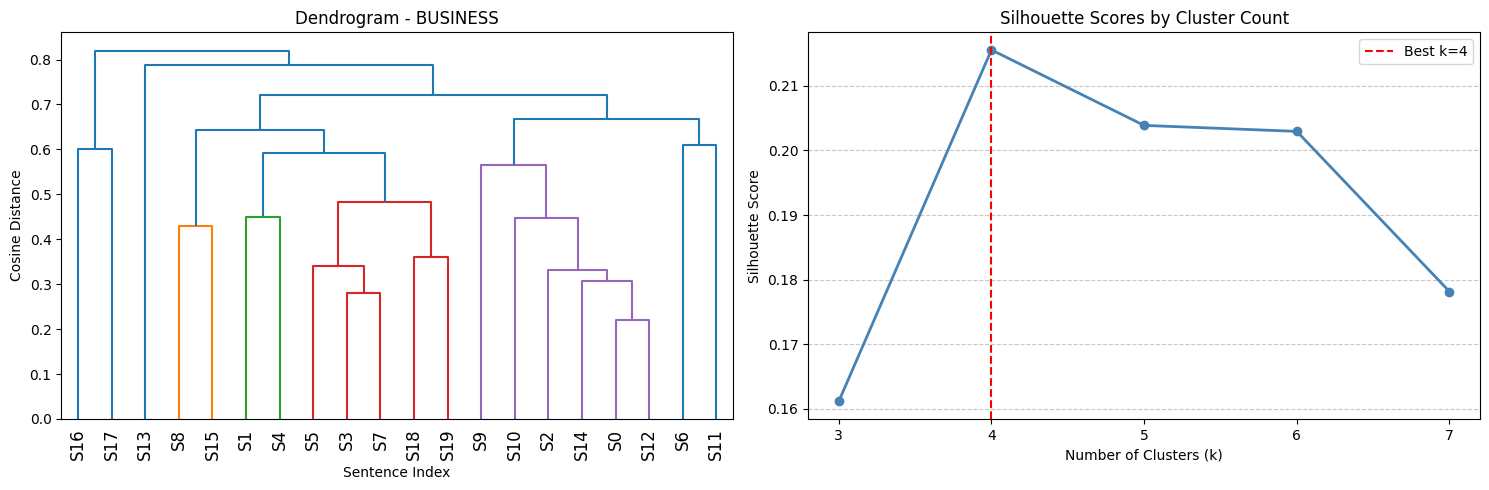


Generating EDA plots (Dendrogram + Silhouette)
Document ID: bbc_entertainment_001 | Category: ENTERTAINMENT


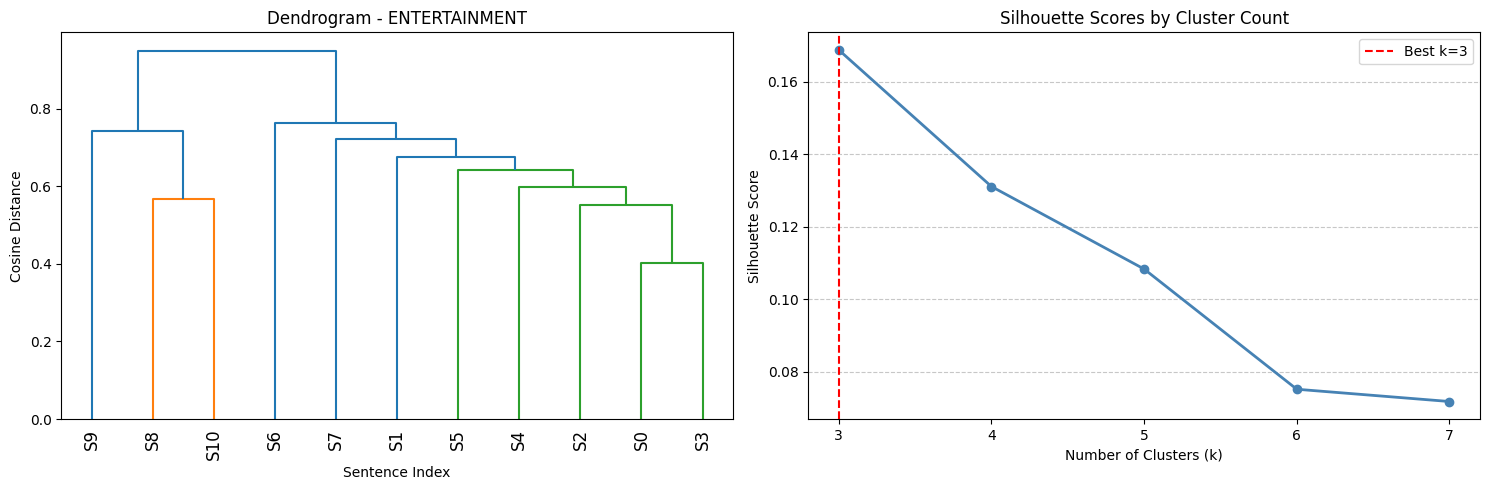


Generating EDA plots (Dendrogram + Silhouette)
Document ID: bbc_politics_001 | Category: POLITICS


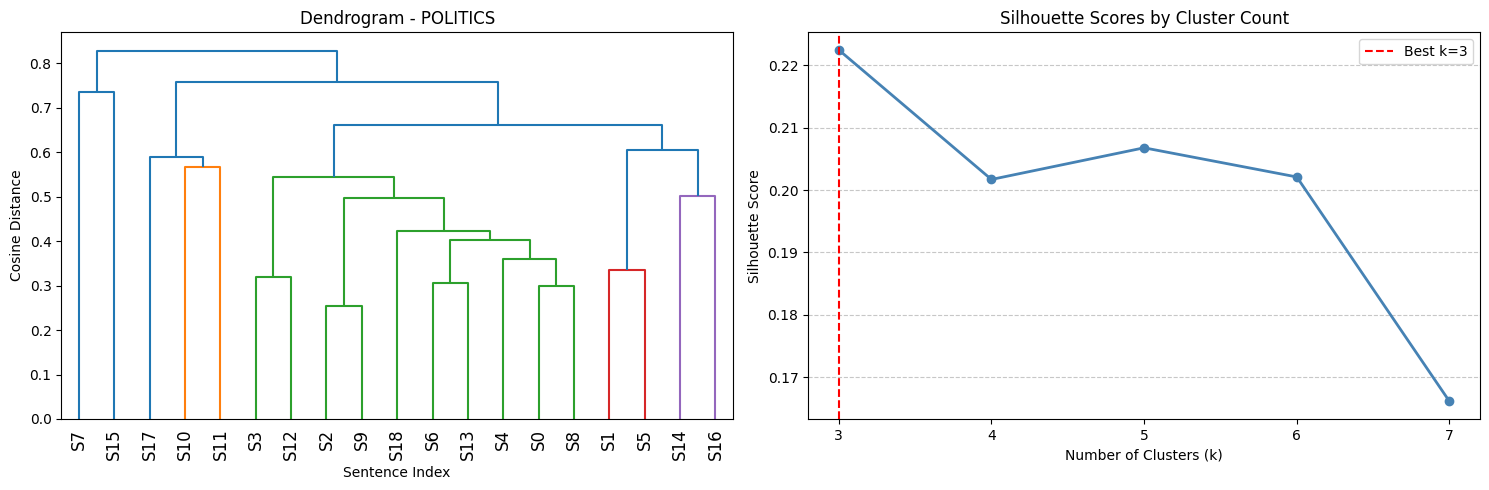


Generating EDA plots (Dendrogram + Silhouette)
Document ID: bbc_sport_001 | Category: SPORT


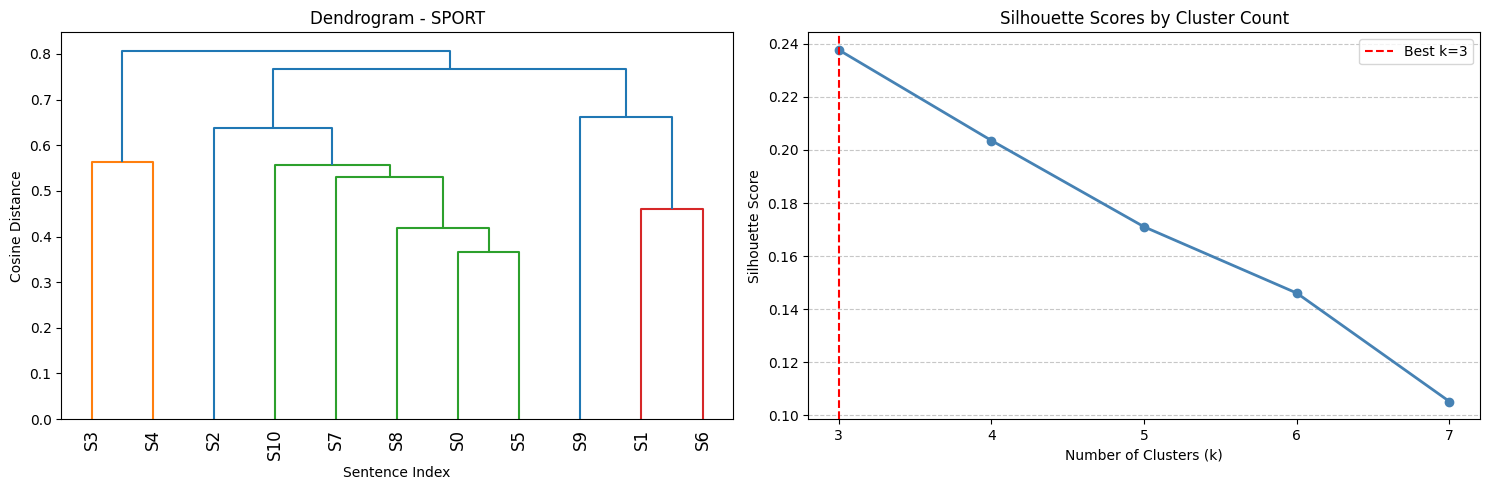


Generating EDA plots (Dendrogram + Silhouette)
Document ID: bbc_tech_001 | Category: TECH


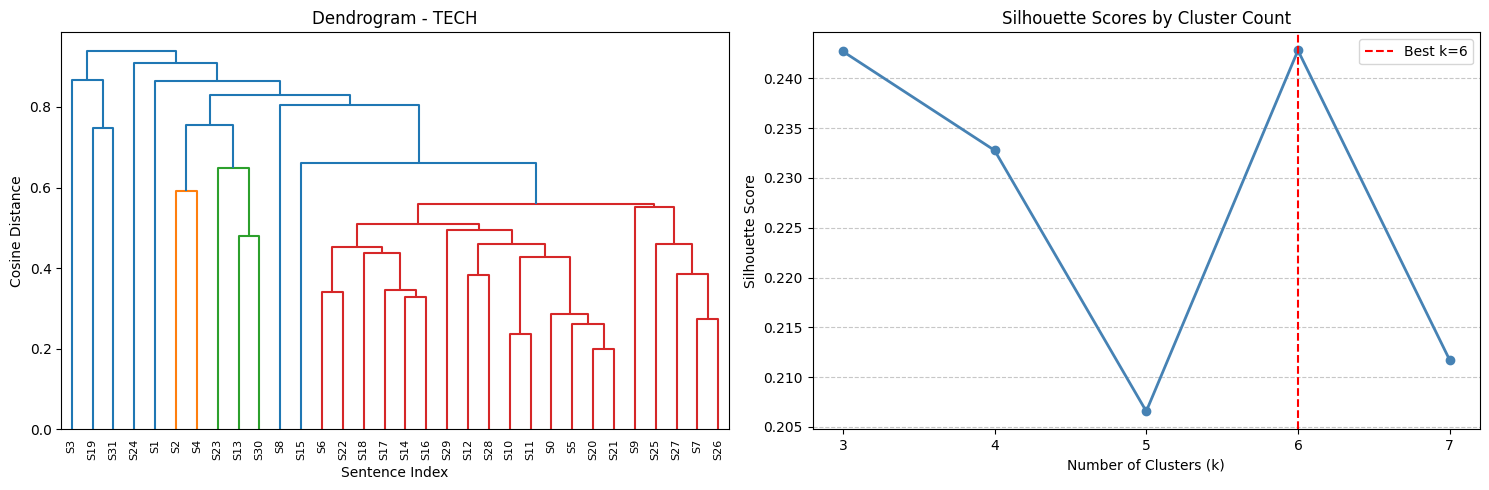


Finished processing all 2225 documents!
First 20 cluster counts saved: [4, 3, 3, 3, 3, 4, 3, 6, 6, 3, 6, 4, 6, 5, 3, 4, 4, 6, 3, 5]


In [23]:
test_encoder = SentenceTransformer("all-MiniLM-L6-v2") 

# Create a list to hold the cluster count for every single document
all_cluster_counts = []

seen_categories = set()

print(f"Extracting category-aware cluster counts for all {len(D)} documents...")

for i, doc in enumerate(D):
    
    category = doc.get('category', 'unknown').upper()
    
    should_plot = False
    if category not in seen_categories:
        should_plot = True
        seen_categories.add(category) 
        
        print(f"\n" + "="*50)
        print(f"Generating EDA plots (Dendrogram + Silhouette)")
        print(f"Document ID: {doc.get('doc_id', 'Unknown')} | Category: {category}")
        print("="*50)

    cluster_args = {"encoder": test_encoder,
                    "plot_dendrogram": should_plot    }
        
    C = sentence_clustering(doc, args=cluster_args)
    
    all_cluster_counts.append(C.get("num_clusters_found", 0))

print(f"\nFinished processing all {len(D)} documents!")
print(f"First 20 cluster counts saved: {all_cluster_counts[:20]}")

**2. Number of p keywords to extract**

Testing get_optimal_p function (Printing 2 documents per category)...

Doc ID                    | Category        | Word Count   | Calculated p
---------------------------------------------------------------------------
bbc_business_001          | business        | 421          | 6           
bbc_business_002          | business        | 384          | 6           
bbc_entertainment_001     | entertainment   | 190          | 4           
bbc_entertainment_002     | entertainment   | 253          | 4           
bbc_politics_001          | politics        | 450          | 7           
bbc_politics_002          | politics        | 379          | 7           
bbc_sport_001             | sport           | 211          | 4           
bbc_sport_002             | sport           | 144          | 4           
bbc_tech_001              | tech            | 672          | 9           
bbc_tech_002              | tech            | 383          | 7           
---------------------------------------

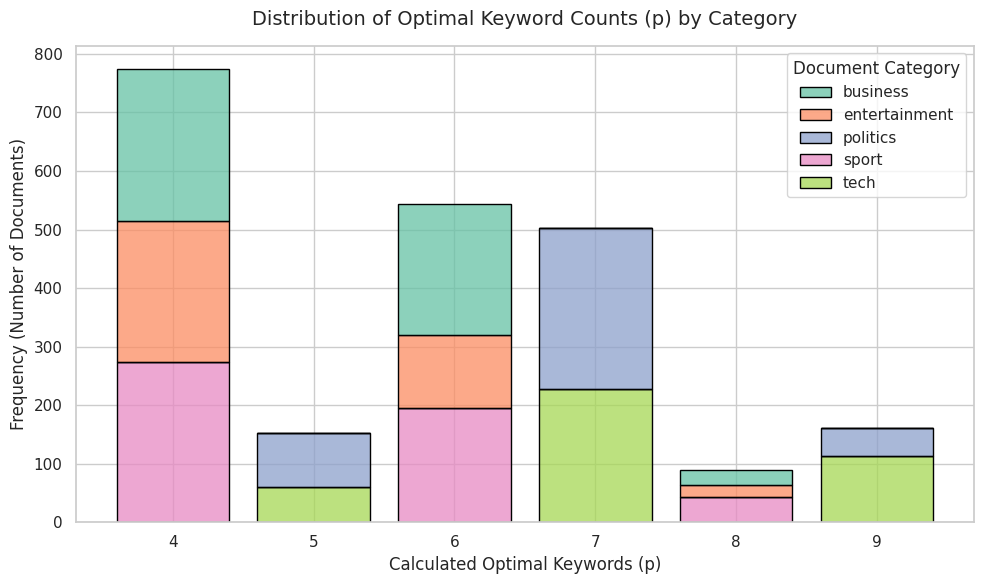

In [24]:
print("Testing get_optimal_p function (Printing 2 documents per category)...\n")
print(f"{'Doc ID':<25} | {'Category':<15} | {'Word Count':<12} | {'Calculated p':<12}")
print("-" * 75) 

# Lists to store data for the loop and the plot
all_optimal_p_values = []
plot_data = [] 
category_counts = {}

# Loop through your entire dataset D
for i, doc in enumerate(D):
    
    optimal_p = get_optimal_p(doc)
    all_optimal_p_values.append(optimal_p)
    
    category = doc.get('category', 'Unknown')
    
    plot_data.append({'Category': category, 'Optimal p': optimal_p})
    
    if category not in category_counts:
        category_counts[category] = 0
        
    if category_counts[category] < 2:
        
        text = doc.get('text', '')
        word_count = len(text.split())
        doc_id = doc.get('doc_id', f"Doc_{i}")
        
        print(f"{str(doc_id):<25} | {str(category):<15} | {word_count:<12} | {optimal_p:<12}")
        
        category_counts[category] += 1

print("-" * 75)
print(f"Finished extracting 'p' for all {len(D)} documents!")

print(f"\nFirst 20 optimal 'p' values:")
print(all_optimal_p_values[:20])

# Stacked Histogram
print("\nGenerating stacked histogram...")

df = pd.DataFrame(plot_data)

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.histplot(data=df, 
                  x='Optimal p', 
                  hue='Category', 
                  multiple='stack', 
                  discrete=True, 
                  shrink=0.8,
                  palette='Set2', 
                  edgecolor='black')

plt.title('Distribution of Optimal Keyword Counts (p) by Category', fontsize=14, pad=15)
plt.xlabel('Calculated Optimal Keywords (p)', fontsize=12)
plt.ylabel('Frequency (Number of Documents)', fontsize=12)

min_p = df['Optimal p'].min()
max_p = df['Optimal p'].max()
plt.xticks(range(int(min_p), int(max_p) + 1))

sns.move_legend(ax, "upper right", title='Document Category', frameon=True)

plt.tight_layout()
plt.show()


<H3>END</H3>